# The precalculus steps under Calc 2, Griffiths, and modern physics

In most "hard" integrals in Griffiths or a modern-physics course, the calculus is one line.
The rest is precalculus: completing the square, a trig identity, exponent and log rules,
partial fractions, a geometric series. That's also where most exam points get lost.

Every derivation below runs through `dgs/precalc_steps.py`:
* each **"=" step** is checked by SymPy to equal the previous one, so a wrong step raises
  `StepError` and is never shown as if it were right;
* each **operation** (integrate, expand in a series, substitute, solve) is checked by redoing
  it forward, or by undoing it backward (sum the series back, differentiate the answer);
* at the end, **Torch autograd** checks the antiderivatives numerically, as a second,
  independent method.

| Precalc skill | Calc 2 technique it unlocks | Where it shows up |
|---|---|---|
| Completing the square | Gaussian integrals | free wave packet (Griffiths QM 2.4), statistics |
| sin² = (1 − cos 2A)/2, product-to-sum | integrals of trig powers, orthogonality | ⟨x⟩ in a box, Fourier series |
| Integration by parts (from the product rule) | ∫ polynomial × trig/exp | expectation values, Laplace transforms |
| Geometric series r/(1 − r) | series inside integrals | Planck spectrum → Stefan–Boltzmann |
| Exponent and log rules | solving exponential equations | half-life, RC circuits |
| Binomial series (1 + q)ᵖ | Taylor approximations | relativistic K → ½mv² |
| 1 + tan² = sec², right triangles | trig substitution | field of a line charge (Griffiths E&M Ex. 2.2) |
| Partial fractions | rational integrals, inverse Laplace | radioactive decay chains |

In [1]:
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import sympy as sp
sp.init_printing(use_unicode=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from dgs import precalc_steps as P
from dgs.precalc_steps import Steps, StepError
pd.set_option("display.max_colwidth", 70); pd.set_option("display.width", 200)

## 0. The precalc toolkit, each identity checked

Each row is an identity you're expected to know cold. The `check` column is SymPy confirming
left − right = 0.

In [2]:
A, B, q, r, k = sp.symbols("A B q r k", real=True)
pp, mm = sp.symbols("p m", positive=True)
ident = [
    ("exponent: e^A e^B = e^(A+B)", sp.exp(A) * sp.exp(B), sp.exp(A + B)),
    ("log: ln(p m) = ln p + ln m", sp.log(pp * mm), sp.log(pp) + sp.log(mm)),
    ("log: ln(p^k) = k ln p", sp.log(pp**k), k * sp.log(pp)),
    ("Pythagorean: sin^2 + cos^2 = 1", sp.sin(A)**2 + sp.cos(A)**2, 1),
    ("1 + tan^2 = sec^2", 1 + sp.tan(A)**2, 1 / sp.cos(A)**2),
    ("double angle: sin 2A = 2 sin A cos A", sp.sin(2 * A), 2 * sp.sin(A) * sp.cos(A)),
    ("power reduction: sin^2 A = (1 - cos 2A)/2", sp.sin(A)**2, (1 - sp.cos(2 * A)) / 2),
    ("power reduction: cos^2 A = (1 + cos 2A)/2", sp.cos(A)**2, (1 + sp.cos(2 * A)) / 2),
    ("product-to-sum: sin A sin B", sp.sin(A) * sp.sin(B), (sp.cos(A - B) - sp.cos(A + B)) / 2),
    ("sum of angles: cos(A + B)", sp.cos(A + B), sp.cos(A) * sp.cos(B) - sp.sin(A) * sp.sin(B)),
    ("complete the square", q**2 + B * q, (q + B / 2)**2 - B**2 / 4),
    ("finite geometric sum (r != 1)", sum(r**j for j in range(6)), (1 - r**6) / (1 - r)),
]
rows = [(name, sp.sstr(lhs), sp.sstr(rhs), P._equal(lhs, rhs)) for name, lhs, rhs in ident]
display(pd.DataFrame(rows, columns=["identity", "left", "right", "check"]))
assert all(r[-1] for r in rows)

,identity,left,right,check
0,exponent: e^A e^B = e^(A+B),exp(A)*exp(B),exp(A + B),True
1,log: ln(p m) = ln p + ln m,log(m*p),log(m) + log(p),True
2,log: ln(p^k) = k ln p,log(p**k),k*log(p),True
3,Pythagorean: sin^2 + cos^2 = 1,sin(A)**2 + cos(A)**2,1,True
4,1 + tan^2 = sec^2,tan(A)**2 + 1,cos(A)**(-2),True
5,double angle: sin 2A = 2 sin A cos A,sin(2*A),2*sin(A)*cos(A),True
6,power reduction: sin^2 A = (1 - cos 2A)/2,sin(A)**2,1/2 - cos(2*A)/2,True
7,power reduction: cos^2 A = (1 + cos 2A)/2,cos(A)**2,cos(2*A)/2 + 1/2,True
8,product-to-sum: sin A sin B,sin(A)*sin(B),cos(A - B)/2 - cos(A + B)/2,True
9,sum of angles: cos(A + B),cos(A + B),-sin(A)*sin(B) + cos(A)*cos(B),True


## 1. Completing the square → Gaussian integral

**Where it shows up:** the free-particle wave packet (Griffiths QM §2.4), the normal distribution, Fourier transforms of Gaussians.

**Gaussian integral: complete the square**

0. *start*: exponent of exp(-a x^2 + b x)

1. *factor out -a*: pull the x^2 coefficient out

2. *add and subtract (b/2a)^2*: half the x-coefficient, squared

3. *perfect square*: x^2 - px + (p/2)^2 = (x - p/2)^2

4. *integrate exp(...) over all x*  [integrate exp(...) over all x]: shift x -> x + b/2a, then the standard result sqrt(pi/a)

,step,skill,expression,why,verified
0,0,start,-a*x**2 + b*x,exponent of exp(-a x^2 + b x),= checked
1,1,factor out -a,-a*(x**2 - b*x/a),pull the x^2 coefficient out,= checked
2,2,add and subtract (b/2a)^2,-a*(x**2 - b*x/a),"half the x-coefficient, squared",= checked
3,3,perfect square,-a*(x - b/(2*a))**2 + b**2/(4*a),x^2 - px + (p/2)^2 = (x - p/2)^2,= checked
4,4,integrate exp(...) over all x,sqrt(pi)*exp(b**2/(4*a))/sqrt(a),"shift x -> x + b/2a, then the standard result sqrt(pi/a)",integrate exp(...) over all x checked


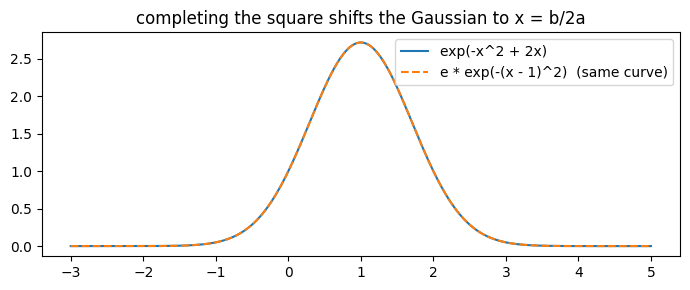

In [3]:
S = P.example_complete_square()
S.show()
display(S.table())
xs = np.linspace(-3, 5, 400)
plt.figure(figsize=(7, 3)); plt.plot(xs, np.exp(-xs**2 + 2 * xs), label="exp(-x^2 + 2x)")
plt.plot(xs, np.e * np.exp(-(xs - 1)**2), "--", label="e * exp(-(x - 1)^2)  (same curve)")
plt.legend(); plt.title("completing the square shifts the Gaussian to x = b/2a"); plt.tight_layout(); plt.show()

## 2. Power reduction + integration by parts → ⟨x⟩ in a box

**Where it shows up:** Knight Ch. 40 / PHYS 106 expectation values. The same moves give ⟨x²⟩ and Δx.

In [4]:
S = P.example_box_mean_x()
S.show()
display(S.table())

**<x> in a box: sin^2 identity + integration by parts**

0. *start*: integrand x |psi_1|^2

1. *power reduction*: sin^2 A = (1 - cos 2A)/2  (precalc identity)

2. *distribute*: split into an easy term and a by-parts term

3. *integrate over [0, L]*  [integrate over [0, L]]: x/L gives L/2; by parts (u = x, dv = cos) gives 0 because sin(2 pi) = 0

,step,skill,expression,why,verified
0,0,start,2*x*sin(pi*x/L)**2/L,integrand x |psi_1|^2,= checked
1,1,power reduction,x*(1 - cos(2*pi*x/L))/L,sin^2 A = (1 - cos 2A)/2 (precalc identity),= checked
2,2,distribute,-x*cos(2*pi*x/L)/L + x/L,split into an easy term and a by-parts term,= checked
3,3,"integrate over [0, L]",L/2,"x/L gives L/2; by parts (u = x, dv = cos) gives 0 because sin(2 pi...","integrate over [0, L] checked"


## 3. Integration by parts, checked by differentiating

**Where it shows up:** it comes from the product rule: (uv)′ = u′v + uv′, then integrate both sides. Checking by differentiating catches sign errors.

**integration by parts: u = x, dv = cos(kx) dx**

0. *start*: uv - integral of v du, with v = sin(kx)/k

1. *finish the easy integral*: integral of sin(kx)/k = -cos(kx)/k^2

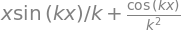

2. *differentiate to check*  [differentiate to check]: d/dx of the antiderivative must give back the integrand

,step,skill,expression,why,verified
0,0,start,"-Integral(sin(k*x)/k, x) + x*sin(k*x)/k","uv - integral of v du, with v = sin(kx)/k",= checked
1,1,finish the easy integral,x*sin(k*x)/k + cos(k*x)/k**2,integral of sin(kx)/k = -cos(kx)/k^2,= checked
2,2,differentiate to check,x*cos(k*x),d/dx of the antiderivative must give back the integrand,differentiate to check checked


In [5]:
S = P.example_by_parts_rule()
S.show()
display(S.table())

## 4. Geometric series inside an integral → Stefan–Boltzmann

**Where it shows up:** blackbody radiation (modern physics): total power ∝ T⁴ with the constant π⁴/15.

**Stefan-Boltzmann: geometric series inside an integral**

0. *start*: Planck integrand (z = h f / k T)

1. *multiply top and bottom by e^-z*: exponent rules

2. *geometric series, |r| = e^-z < 1*  [geometric series, |r| = e^-z < 1]: r/(1 - r) = r + r^2 + r^3 + ... with r = e^-z (precalc geometric series); checked by summing it back

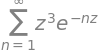

3. *integrate each term over [0, inf)*  [integrate each term over [0, inf)]: every term is positive, so sum and integral may be swapped (Tonelli); integral of z^3 e^{-nz} = 3!/n^4

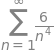

4. *zeta(4) = pi^4/90*  [zeta(4) = pi^4/90]: 6 * pi^4/90

,step,skill,expression,why,verified
0,0,start,z**3/(exp(z) - 1),Planck integrand (z = h f / k T),= checked
1,1,multiply top and bottom by e^-z,z**3*exp(-z)/(1 - exp(-z)),exponent rules,= checked
2,2,"geometric series, |r| = e^-z < 1","Sum(z**3*exp(-n*z), (n, 1, oo))",r/(1 - r) = r + r^2 + r^3 + ... with r = e^-z (precalc geometric s...,"geometric series, |r| = e^-z < 1 checked"
3,3,"integrate each term over [0, inf)","Sum(6/n**4, (n, 1, oo))","every term is positive, so sum and integral may be swapped (Tonell...","integrate each term over [0, inf) checked"
4,4,zeta(4) = pi^4/90,pi**4/15,6 * pi^4/90,zeta(4) = pi^4/90 checked


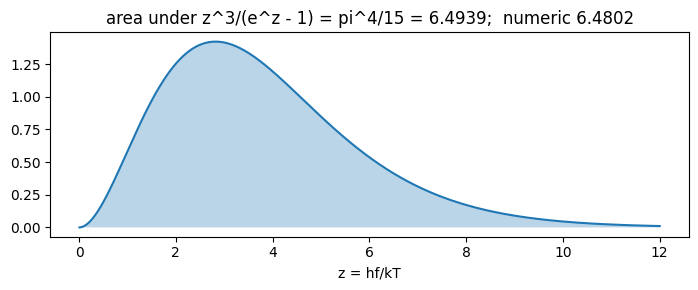

In [6]:
S = P.example_stefan_boltzmann()
S.show()
display(S.table())
zs = np.linspace(0.01, 12, 400)
plt.figure(figsize=(7, 3)); plt.plot(zs, zs**3 / np.expm1(zs)); plt.fill_between(zs, zs**3 / np.expm1(zs), alpha=0.3)
plt.title(f"area under z^3/(e^z - 1) = pi^4/15 = {math.pi**4 / 15:.4f};  numeric {np.trapezoid(zs**3 / np.expm1(zs), zs):.4f}")
plt.xlabel("z = hf/kT"); plt.tight_layout(); plt.show()

## 5. Exponent and log rules → half-life

**Where it shows up:** radioactive decay and RC/RL circuits (EEE 117: the time to fall to half is τ ln 2). Equation steps are checked by comparing solution sets.

In [7]:
S = P.example_half_life()
S.show()
display(S.table())

**half-life: exponent and log rules**

0. *start*: decay law at the half-life

1. *divide both sides by N0*: 

2. *take ln of both sides*: ln(e^A) = A

3. *log rule ln(1/2) = -ln 2*: ln(1/q) = -ln q

4. *solve for t*  [solve for t]: divide by -lambda

,step,skill,expression,why,verified
0,0,start,"Eq(N_0*exp(-lambda*t), N_0/2)",decay law at the half-life,= checked
1,1,divide both sides by N0,"Eq(exp(-lambda*t), 1/2)",,= checked
2,2,take ln of both sides,"Eq(-lambda*t, -log(2))",ln(e^A) = A,= checked
3,3,log rule ln(1/2) = -ln 2,"Eq(-lambda*t, -log(2))",ln(1/q) = -ln q,= checked
4,4,solve for t,log(2)/lambda,divide by -lambda,solve for t checked


## 6. Binomial series → relativistic K becomes ½mv²

**Where it shows up:** PHYS 106 relativity: why Newton works at low speed, and how large the first correction is.

**relativistic K -> (1/2) m v^2: binomial series**

0. *start*: K = (gamma - 1) m c^2

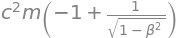

1. *negative exponent*: 1/sqrt(q) = q^(-1/2)

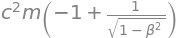

2. *binomial series (1 + q)^p = 1 + p q + p(p-1)/2 q^2 + ...*  [binomial series (1 + q)^p = 1 + p q + p(p-1)/2 q^2 + ...]: q = -beta^2, p = -1/2, keep two terms

3. *substitute beta = v/c*  [substitute beta = v/c]: leading term is the Newtonian (1/2) m v^2; the next is the first relativistic correction

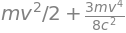

,step,skill,expression,why,verified
0,0,start,c**2*m*(-1 + 1/sqrt(1 - beta**2)),K = (gamma - 1) m c^2,= checked
1,1,negative exponent,c**2*m*(-1 + 1/sqrt(1 - beta**2)),1/sqrt(q) = q^(-1/2),= checked
2,2,binomial series (1 + q)^p = 1 + p q + p(p-1)/2 q^2 + ...,c**2*m*(3*beta**4/8 + beta**2/2),"q = -beta^2, p = -1/2, keep two terms",binomial series (1 + q)^p = 1 + p q + p(p-1)/2 q^2 + ... checked
3,3,substitute beta = v/c,m*v**2/2 + 3*m*v**4/(8*c**2),leading term is the Newtonian (1/2) m v^2; the next is the first r...,substitute beta = v/c checked


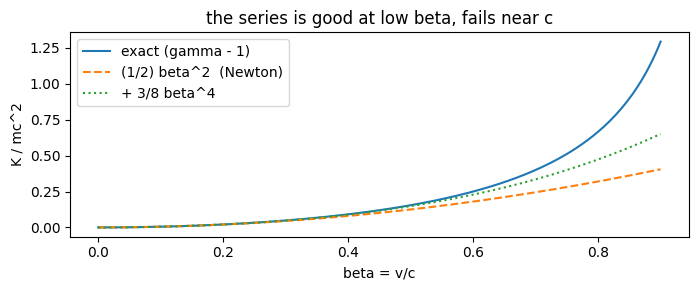

beta = 0.1: Newton's (1/2) m v^2 is 0.75% low
beta = 0.5: Newton's (1/2) m v^2 is 19.20% low
beta = 0.9: Newton's (1/2) m v^2 is 68.71% low


In [8]:
S = P.example_relativistic_ke()
S.show()
display(S.table())
bs = np.linspace(0, 0.9, 200)
exact = 1 / np.sqrt(1 - bs**2) - 1
plt.figure(figsize=(7, 3)); plt.plot(bs, exact, label="exact (gamma - 1)")
plt.plot(bs, bs**2 / 2, "--", label="(1/2) beta^2  (Newton)"); plt.plot(bs, bs**2 / 2 + 3 * bs**4 / 8, ":", label="+ 3/8 beta^4")
plt.xlabel("beta = v/c"); plt.ylabel("K / mc^2"); plt.legend(); plt.title("the series is good at low beta, fails near c")
plt.tight_layout(); plt.show()
for b0 in (0.1, 0.5, 0.9):
    ex0 = 1 / math.sqrt(1 - b0**2) - 1
    print(f"beta = {b0}: Newton's (1/2) m v^2 is {(ex0 - b0**2 / 2) / ex0:.2%} low")

## 7. Trig substitution → field of a finite line charge

**Where it shows up:** Griffiths E&M Ex. 2.2 (the field of a finite line charge). Note the step that needs cos θ > 0: the substitution only works on −π/2 < θ < π/2.

**finite line charge: trig substitution z = s tan(theta)**

0. *start*: integrand of the field of a line charge (Griffiths Ex. 2.2)

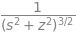

1. *substitute z = s tan(theta), dz = s sec^2(theta) d theta*  [substitute z = s tan(theta), dz = s sec^2(theta) d theta]: 1 + tan^2 = sec^2 collapses the root to |sec theta|^3; for -pi/2 < theta < pi/2 (the range of arctan) cos theta > 0, so |cos theta| = cos theta

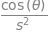

2. *integrate in theta*  [integrate in theta]: integral of cos = sin

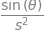

3. *back-substitute with the triangle: sin(theta) = z / sqrt(z^2 + s^2)*  [back-substitute with the triangle: sin(theta) = z / sqrt(z^2 + s^2)]: opposite / hypotenuse

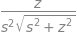

4. *differentiate to check*  [differentiate to check]: gives back the integrand

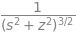

,step,skill,expression,why,verified
0,0,start,(s**2 + z**2)**(-3/2),integrand of the field of a line charge (Griffiths Ex. 2.2),= checked
1,1,"substitute z = s tan(theta), dz = s sec^2(theta) d theta",cos(theta)/s**2,1 + tan^2 = sec^2 collapses the root to |sec theta|^3; for -pi/2 <...,"substitute z = s tan(theta), dz = s sec^2(theta) d theta checked"
2,2,integrate in theta,sin(theta)/s**2,integral of cos = sin,integrate in theta checked
3,3,back-substitute with the triangle: sin(theta) = z / sqrt(z^2 + s^2),z/(s**2*sqrt(s**2 + z**2)),opposite / hypotenuse,back-substitute with the triangle: sin(theta) = z / sqrt(z^2 + s^2...
4,4,differentiate to check,(s**2 + z**2)**(-3/2),gives back the integrand,differentiate to check checked


In [9]:
S = P.example_trig_sub()
S.show()
display(S.table())

## 8. Partial fractions → a decay chain A → B → C

**Where it shows up:** modern physics decay chains and EEE 117 inverse Laplace transforms: two exponentials whose difference rises, then falls.

**two-step decay chain: partial fractions**

0. *start*: Laplace-domain factor of the A -> B -> C chain

1. *partial fractions*: A/(p + k1) + B/(p + k2); cover-up gives A = -B = 1/(k2 - k1)

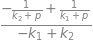

2. *invert each piece: 1/(p + k) <-> e^{-k t}*  [invert each piece: 1/(p + k) <-> e^{-k t}]: the Bateman shape: rises, then decays

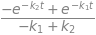

,step,skill,expression,why,verified
0,0,start,1/((k_1 + p)*(k_2 + p)),Laplace-domain factor of the A -> B -> C chain,= checked
1,1,partial fractions,(-1/(k_2 + p) + 1/(k_1 + p))/(-k_1 + k_2),A/(p + k1) + B/(p + k2); cover-up gives A = -B = 1/(k2 - k1),= checked
2,2,invert each piece: 1/(p + k) <-> e^{-k t},(-exp(-k_2*t) + exp(-k_1*t))/(-k_1 + k_2),"the Bateman shape: rises, then decays",invert each piece: 1/(p + k) <-> e^{-k t} checked


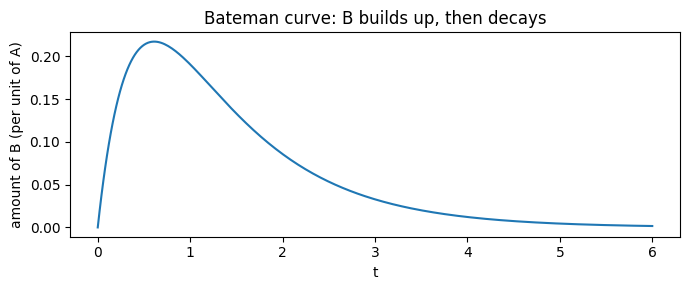

In [10]:
S = P.example_partial_fractions()
S.show()
display(S.table())
ts = np.linspace(0, 6, 300); k1v, k2v = 1.0, 2.5
plt.figure(figsize=(7, 3)); plt.plot(ts, (np.exp(-k1v * ts) - np.exp(-k2v * ts)) / (k2v - k1v))
plt.xlabel("t"); plt.ylabel("amount of B (per unit of A)"); plt.title("Bateman curve: B builds up, then decays"); plt.tight_layout(); plt.show()

## 9. Mistake gallery: what the checker catches

These are real, common errors. Each one is fed to the engine, and each one is rejected.

In [11]:
from dgs.precalc_steps import a, b, x, t, lam
mistakes = [
    ("freshman's dream: (x + b)^2 = x^2 + b^2", lambda: Steps("m").start((x + b)**2).eq("?", x**2 + b**2)),
    ("power reduction with the wrong sign", lambda: Steps("m").start(sp.sin(x)**2).eq("?", (1 + sp.cos(2 * x)) / 2)),
    ("completing the square: b^2/2a instead of b^2/4a",
     lambda: Steps("m").start(-a * x**2 + b * x).eq("?", -a * (x - b / (2 * a))**2 + b**2 / (2 * a))),
    ("ln(1/2) = +ln 2", lambda: Steps("m", unknown=t).start(sp.Eq(sp.exp(-lam * t), sp.Rational(1, 2))).eq("?", sp.Eq(-lam * t, sp.log(2)))),
    ("antiderivative of x cos(kx) with the wrong sign",
     lambda: Steps("m").start(x * sp.cos(2 * x)).op("?", x * sp.sin(2 * x) / 2 - sp.cos(2 * x) / 4, "", check=lambda e: sp.integrate(e, x))),
]
rows = []
for name, attempt in mistakes:
    try:
        attempt(); rows.append((name, "NOT caught"))
    except StepError:
        rows.append((name, "caught: StepError"))
display(pd.DataFrame(rows, columns=["mistake", "result"]))
assert all(r[1].startswith("caught") for r in rows)

,mistake,result
0,freshman's dream: (x + b)^2 = x^2 + b^2,caught: StepError
1,power reduction with the wrong sign,caught: StepError
2,completing the square: b^2/2a instead of b^2/4a,caught: StepError
3,ln(1/2) = +ln 2,caught: StepError
4,antiderivative of x cos(kx) with the wrong sign,caught: StepError


## 10. A second, independent check: Torch autograd

Autograd applies the chain rule automatically, the same machinery that trains neural
networks. Differentiating each antiderivative numerically must give back the integrand.
This uses a different method from SymPy, so the two can't share a bug.

In [12]:
try:
    import torch
    zz = torch.linspace(-3, 3, 201, dtype=torch.float64, requires_grad=True)
    checks = {
        "by parts: x sin(kx)/k + cos(kx)/k^2 -> x cos(kx)": (lambda v: v * torch.sin(2.3 * v) / 2.3 + torch.cos(2.3 * v) / 2.3**2,
                                                           lambda v: v * torch.cos(2.3 * v)),
        "trig sub: z/(s^2 sqrt(z^2+s^2)) -> (z^2+s^2)^(-3/2)": (lambda v: v / (0.7**2 * torch.sqrt(v**2 + 0.7**2)),
                                                              lambda v: (v**2 + 0.7**2) ** -1.5),
        "Gaussian antiderivative check: d/dx erf": (lambda v: torch.erf(v), lambda v: 2 / math.sqrt(math.pi) * torch.exp(-v**2)),
        "chain rule: d/dt e^(-lambda t) = -lambda e^(-lambda t)": (lambda v: torch.exp(-0.8 * v), lambda v: -0.8 * torch.exp(-0.8 * v)),
    }
    rows = []
    for name, (F, f) in checks.items():
        (dF,) = torch.autograd.grad(F(zz).sum(), zz)
        rows.append((name, float((dF - f(zz.detach())).abs().max())))
    display(pd.DataFrame(rows, columns=["antiderivative", "max |autograd - integrand|"]))
    print("torch", torch.__version__, "| device used: cpu")
except ImportError:
    print("torch not installed: skipping the autograd cross-check (SymPy checks above still stand).")

,antiderivative,max |autograd - integrand|
0,by parts: x sin(kx)/k + cos(kx)/k^2 -> x cos(kx),4.440892e-16
1,trig sub: z/(s^2 sqrt(z^2+s^2)) -> (z^2+s^2)^(-3/2),4.440892e-16
2,Gaussian antiderivative check: d/dx erf,0.000000e+00
3,chain rule: d/dt e^(-lambda t) = -lambda e^(-lambda t),0.000000e+00


torch 2.11.0+cu128 | device used: cpu


## Practice (my own problems: do the precalc step first)

1. Complete the square in −3x² + 12x, then find ∫e^(−3x²+12x) dx over all x.
2. Use power reduction to find ∫₀^π cos²(x) dx.
3. Solve 2^(t/5) = 50 for t with log rules.
4. Expand (1 − x)^(−1/2) to second order and use it to approximate 1/√0.98.
5. Split 1/(x² − 1) into partial fractions, and integrate it from 2 to 3.

Each answer below is built with the step engine, so the work is checked too.

In [13]:
xx, tt = sp.symbols("x t", real=True)
S1 = Steps("1").start(-3 * xx**2 + 12 * xx).eq("factor", -3 * (xx**2 - 4 * xx)).eq("complete", -3 * (xx - 2)**2 + 12)
print("1.", S1.result, "-> integral =", sp.simplify(sp.integrate(sp.exp(S1.result), (xx, -sp.oo, sp.oo))))
S2 = Steps("2").start(sp.cos(xx)**2).eq("power reduction", (1 + sp.cos(2 * xx)) / 2)
print("2.", sp.integrate(S2.result, (xx, 0, sp.pi)))
S3 = Steps("3", unknown=tt).start(sp.Eq(2**(tt / 5), 50)).eq("ln both sides", sp.Eq(tt / 5 * sp.log(2), sp.log(50)))
t3 = 5 * sp.log(50) / sp.log(2)
assert P._equal(sp.solve(S3.result, tt)[0], t3)
print("3. t = 5 ln 50 / ln 2 =", sp.N(t3, 5))
ser = sp.series((1 - xx)**sp.Rational(-1, 2), xx, 0, 3).removeO()
print("4.", ser, "-> at x = 0.02:", sp.N(ser.subs(xx, 0.02), 8), " exact:", sp.N(1 / sp.sqrt(0.98), 8))
S5 = Steps("5").start(1 / (xx**2 - 1)).eq("partial fractions", (1 / (xx - 1) - 1 / (xx + 1)) / 2)
print("5.", S5.result, "-> integral from 2 to 3 =", sp.simplify(sp.integrate(S5.result, (xx, 2, 3))))

1. 12 - 3*(x - 2)**2 -> integral = sqrt(3)*sqrt(pi)*exp(12)/3
2. pi/2
3. t = 5 ln 50 / ln 2 = 28.219
4. 3*x**2/8 + x/2 + 1 -> at x = 0.02: 1.0101500  exact: 1.0101525
5. -1/(2*(x + 1)) + 1/(2*(x - 1)) -> integral from 2 to 3 = -log(2)/2 + log(3)/2


## Checklist

- [ ] Before integrating, ask which precalc move turns this into a known form: square, identity, series, fractions, or substitution.
- [ ] Every "=" must really be equal. Equation steps must keep the same solutions.
- [ ] Substitutions have domains: trig sub needs −π/2 < θ < π/2, and the geometric series needs |r| < 1.
- [ ] Check an antiderivative by differentiating it (SymPy, Torch autograd, or by hand).
- [ ] If SymPy hangs, use structure (substitution, matrices, known series) instead of brute-force `simplify`.